# Car Price Prediction with Regularised Regression (Ridge and Lasso)

**Goal:** predict car prices as accurately as possible using **all** the features, and compare regularised regression (Ridge, Lasso) with ordinary least squares (OLS).

This notebook is the prediction-focused companion to `car_price_mlr.ipynb`, which covers exploratory analysis, assumption checks and interpretation of a smaller multiple linear regression model. Both notebooks use the same data, cleaning and train/test split (20% test, `random_state=42`), so their test scores are directly comparable.

**Workflow**

1. Clean the data and extract the car brand.
2. Hold out 20% of the cars as a test set before any modelling.
3. Compare four models with repeated 5-fold cross-validation on the training set, and pick the one with the lowest CV error.
4. Evaluate the chosen model once on the test set, check its residuals, and measure which features drive its predictions.

# 1. Setup

In [1]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from sklearn.compose import ColumnTransformer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LassoCV, LinearRegression, RidgeCV
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error, r2_score, root_mean_squared_error
from sklearn.model_selection import RepeatedKFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from statsmodels.stats.outliers_influence import variance_inflation_factor

sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 50)
pd.options.display.float_format = '{:,.4f}'.format

RANDOM_STATE = 42  # same split and seed as car_price_mlr.ipynb

# Some categories have only 1-2 cars (e.g. a brand or engine type). When one of them falls only in a
# validation fold, the one-hot encoder has never seen it and encodes it as all zeros, i.e. as the
# reference category. That is the intended behaviour, so only this specific warning is silenced.
warnings.filterwarnings('ignore', message='Found unknown categories', category=UserWarning)

# 2. Load and clean the data

In [2]:
df = pd.read_csv('CarPrice_Assignment.csv')
df = df.drop(columns=['car_ID'])  # row identifier, no predictive meaning

# The first word of CarName is the brand. Lower-case it, then fix the misspellings.
brand_typos = {
    'maxda': 'mazda',
    'porcshce': 'porsche',
    'toyouta': 'toyota',
    'vokswagen': 'volkswagen',
    'vw': 'volkswagen',
}
df['brand'] = df['CarName'].str.split(' ').str[0].str.lower().replace(brand_typos)
df = df.drop(columns=['CarName'])  # the model name is too specific to use (most are unique)

pd.Series({
    'rows': df.shape[0],
    'columns': df.shape[1],
    'brands': df['brand'].nunique(),
    'duplicate rows': df.duplicated().sum(),
    'missing values': df.isna().sum().sum(),
}).to_frame('value')

,value
rows,205
columns,25
brands,22
duplicate rows,0
missing values,0


205 cars, 22 brands after cleaning, and no duplicates or missing values. `car_price_mlr.ipynb` explores the data in detail; this notebook goes straight to modelling.

# 3. Features and train/test split

In [3]:
target = 'price'
X = df.drop(columns=[target])
y = df[target]

numeric_features = X.select_dtypes(include='number').columns.tolist()
categorical_features = X.select_dtypes(exclude='number').columns.tolist()

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)

print(f"Numeric features ({len(numeric_features)}): {numeric_features}")
print(f"Categorical features ({len(categorical_features)}): {categorical_features}")
print(f"Training set: {len(X_train)} cars | Test set: {len(X_test)} cars")

Numeric features (14): ['symboling', 'wheelbase', 'carlength', 'carwidth', 'carheight', 'curbweight', 'enginesize', 'boreratio', 'stroke', 'compressionratio', 'horsepower', 'peakrpm', 'citympg', 'highwaympg']
Categorical features (10): ['fueltype', 'aspiration', 'doornumber', 'carbody', 'drivewheel', 'enginelocation', 'enginetype', 'cylindernumber', 'fuelsystem', 'brand']
Training set: 164 cars | Test set: 41 cars


The test set is used once, in Section 6. All model choices are made with cross-validation on the 164 training cars.

# 4. Why regularisation? Multicollinearity in the numeric features

The variance inflation factor (VIF) shows how much each numeric feature overlaps with the others. It is computed on the training set only.

In [4]:
X_num = sm.add_constant(X_train[numeric_features])
vif = pd.Series(
    [variance_inflation_factor(X_num.values, i) for i in range(X_num.shape[1])],
    index=X_num.columns,
    name='VIF',
).drop('const')  # the intercept's VIF is not meaningful
vif.sort_values(ascending=False).to_frame()

,VIF
citympg,25.8639
highwaympg,20.1766
curbweight,15.4634
carlength,8.7922
wheelbase,8.4213
horsepower,7.8342
enginesize,6.6960
carwidth,5.0527
compressionratio,2.2732
carheight,2.2486


Several features have VIFs well above the usual threshold of 5 (fuel economy, size and weight measures overlap heavily). With all of them in one OLS model, plus dozens of dummy variables for the categories, the coefficients become unstable.

**Ridge** regression adds a penalty on the size of the coefficients, which shrinks correlated coefficients toward each other and keeps them stable. **Lasso** uses a different penalty that can shrink some coefficients exactly to zero, so it also selects features. In both, the penalty strength (alpha) is chosen by internal cross-validation. Features are standardised first so the penalty treats them equally.

# 5. Model comparison with cross-validation

In [5]:
def full_preprocessor():
    return ColumnTransformer([
        ('num', StandardScaler(), numeric_features),
        ('cat', OneHotEncoder(handle_unknown='ignore', drop='first', sparse_output=False), categorical_features),
    ])


baseline_features = ['horsepower', 'curbweight', 'enginesize']
models = {
    'OLS: hp + weight + engine (original baseline)': Pipeline([
        ('preprocess', ColumnTransformer([('num', StandardScaler(), baseline_features)])),
        ('model', LinearRegression()),
    ]),
    'OLS: all features': Pipeline([
        ('preprocess', full_preprocessor()),
        ('model', LinearRegression()),
    ]),
    'Ridge: all features': Pipeline([
        ('preprocess', full_preprocessor()),
        ('model', RidgeCV(alphas=np.logspace(-3, 3, 50))),
    ]),
    'Lasso: all features': Pipeline([
        ('preprocess', full_preprocessor()),
        ('model', LassoCV(alphas=np.logspace(-3, 3, 80), cv=5, max_iter=50_000, random_state=RANDOM_STATE)),
    ]),
}

# 5-fold CV repeated 5 times = 25 fits per model. The whole pipeline (scaling, encoding, alpha search)
# is refitted inside every fold, so no information from the validation fold leaks into training.
cv = RepeatedKFold(n_splits=5, n_repeats=5, random_state=RANDOM_STATE)
scoring = {
    'R2': 'r2',
    'RMSE': 'neg_root_mean_squared_error',
    'MAE': 'neg_mean_absolute_error',
    'MAPE': 'neg_mean_absolute_percentage_error',
}

cv_rows = {}
for name, pipe in models.items():
    scores = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring)
    cv_rows[name] = {
        'CV R2': scores['test_R2'].mean(),
        'CV RMSE': -scores['test_RMSE'].mean(),
        'CV RMSE sd': scores['test_RMSE'].std(),
        'CV MAE': -scores['test_MAE'].mean(),
        'CV MAPE %': -100 * scores['test_MAPE'].mean(),
    }

cv_results = pd.DataFrame(cv_rows).T.sort_values('CV RMSE')
cv_results

,CV R2,CV RMSE,CV RMSE sd,CV MAE,CV MAPE %
Ridge: all features,0.8969,"2,373.4522",527.4494,"1,650.7386",12.9700
Lasso: all features,0.8764,"2,566.9311",592.7532,"1,771.3430",13.8143
OLS: all features,0.8514,"2,753.7236",773.9200,"1,801.9121",14.0482
OLS: hp + weight + engine (original baseline),0.7757,"3,510.0888",475.5447,"2,463.2341",17.8035


In [6]:
# Choose the model with the lowest cross-validated RMSE. The test set plays no part in this choice.
final_name = cv_results['CV RMSE'].idxmin()
final_model = models[final_name]
print(f"Selected by CV: {final_name}")

Selected by CV: Ridge: all features


- **All three full-feature models beat the original three-feature baseline**, cutting CV RMSE from about \$3,510 to \$2,370–\$2,750.
- **Ridge is clearly best:** the lowest CV RMSE (about \$2,370), lowest MAPE (13.0%), and less variation between folds than plain OLS.
- **Plain OLS on all features is the least stable** of the full models (CV RMSE sd about \$770). That is the multicollinearity from Section 4 at work: unpenalised coefficients swing from fold to fold.
- **Lasso** sits in between. Zeroing out coefficients costs it some accuracy here, because many features carry a little information each.

# 6. Final model on the test set

In [7]:
def price_metrics(actual, pred):
    return {
        'R2': r2_score(actual, pred),
        'RMSE': root_mean_squared_error(actual, pred),
        'MAE': mean_absolute_error(actual, pred),
        'MAPE %': 100 * mean_absolute_percentage_error(actual, pred),
    }


final_model.fit(X_train, y_train)
y_train_pred = final_model.predict(X_train)
y_test_pred = final_model.predict(X_test)

alpha = final_model.named_steps['model'].alpha_ if hasattr(final_model.named_steps['model'], 'alpha_') else None
if alpha is not None:
    print(f"Penalty strength chosen by internal CV: alpha = {alpha:.4f}")

pd.DataFrame({
    'train': price_metrics(y_train, y_train_pred),
    'test': price_metrics(y_test, y_test_pred),
}).T

Penalty strength chosen by internal CV: alpha = 0.4942


,R2,RMSE,MAE,MAPE %
train,0.9705,"1,325.8764","1,003.7252",8.5110
test,0.9037,"2,756.6123","1,893.3360",16.1131


In [8]:
# For reference only: every candidate refitted on the training set and scored on the test set.
# This is reported after the choice was made, and is not used to change it.
test_rows = {}
for name, pipe in models.items():
    pipe.fit(X_train, y_train)
    test_rows[name] = price_metrics(y_test, pipe.predict(X_test))
pd.DataFrame(test_rows).T.sort_values('RMSE')

,R2,RMSE,MAE,MAPE %
OLS: all features,0.9097,"2,669.9339","1,763.5660",15.0094
Ridge: all features,0.9037,"2,756.6123","1,893.3360",16.1131
Lasso: all features,0.8866,"2,992.5471","2,142.5891",19.3323
OLS: hp + weight + engine (original baseline),0.8208,"3,761.0816","2,722.1017",21.5503


**Ridge on the test set:** R² 0.904, RMSE about \$2,760, MAE about \$1,890. The gap between training R² (0.971) and test R² shows some overfitting, which is expected with about 60 columns after one-hot encoding and only 164 training cars.

**Plain OLS on all features happens to score slightly better on this test set** (R² 0.910). The choice of Ridge was made with 25 CV fits **before** the test set was used. With only 41 test cars, a gap this size is within the noise, and switching models after seeing the test score would make the reported score optimistic. So the choice stands.

## 6.1 Residual checks

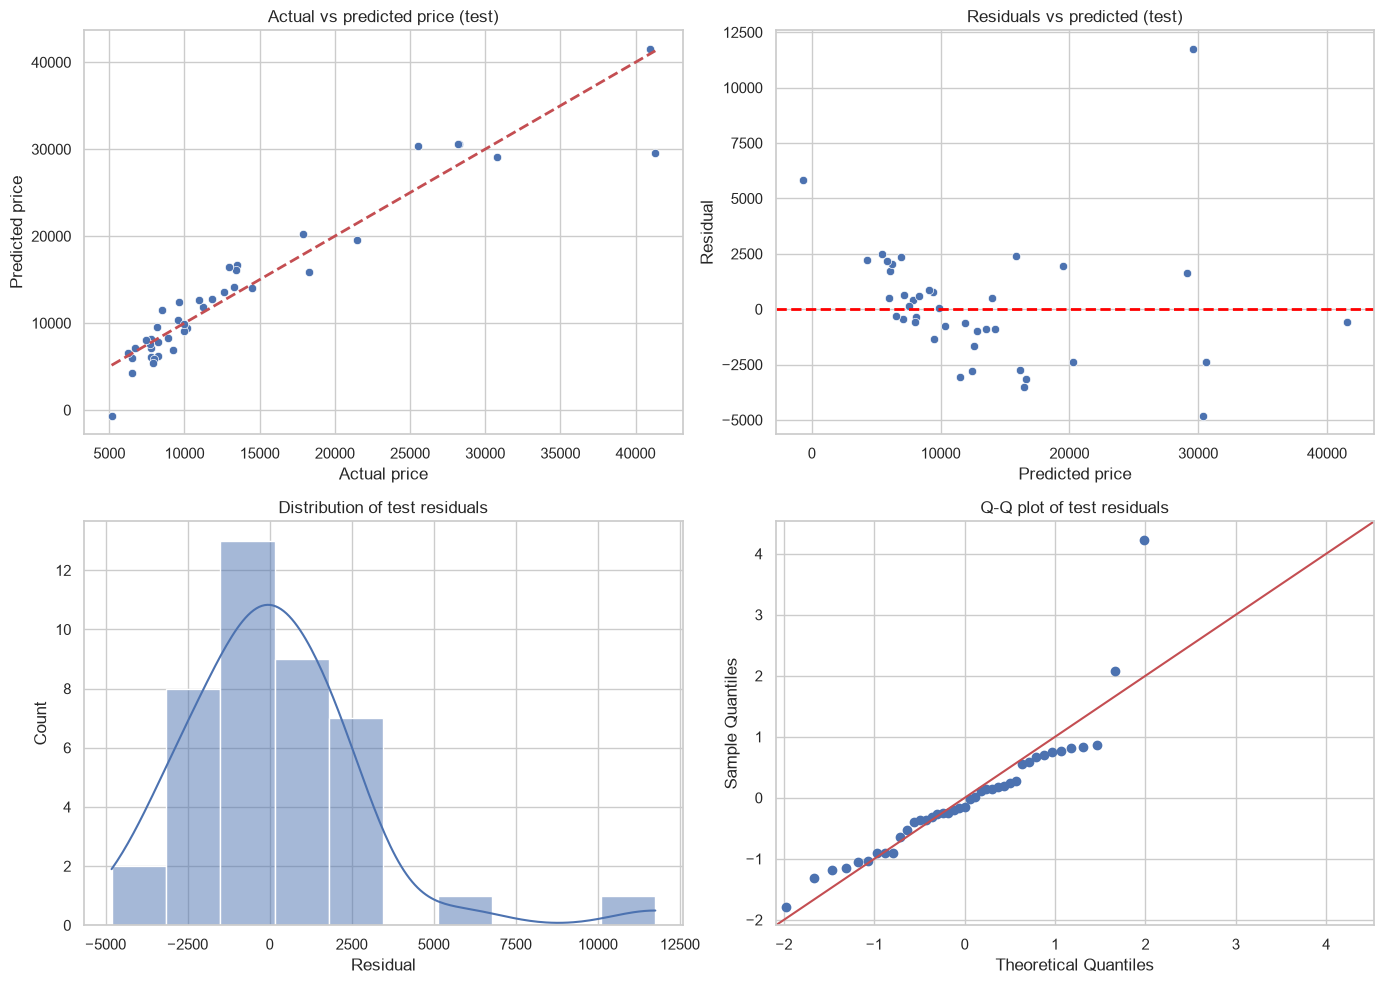

In [9]:
test_residuals = y_test - y_test_pred

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
sns.scatterplot(x=y_test, y=y_test_pred, ax=axes[0, 0])
lims = [y_test.min(), y_test.max()]
axes[0, 0].plot(lims, lims, 'r--', lw=2)
axes[0, 0].set(title='Actual vs predicted price (test)', xlabel='Actual price', ylabel='Predicted price')

sns.scatterplot(x=y_test_pred, y=test_residuals, ax=axes[0, 1])
axes[0, 1].axhline(0, color='red', linestyle='--', lw=2)
axes[0, 1].set(title='Residuals vs predicted (test)', xlabel='Predicted price', ylabel='Residual')

sns.histplot(test_residuals, kde=True, ax=axes[1, 0])
axes[1, 0].set(title='Distribution of test residuals', xlabel='Residual')

sm.qqplot(test_residuals, line='45', fit=True, ax=axes[1, 1])
axes[1, 1].set_title('Q-Q plot of test residuals')

plt.tight_layout()
plt.show()

- **Predictions track actual prices well** for most cars, but errors grow with price: the residuals spread out more above about \$15k.
- **The cheapest test car gets a negative predicted price** (about −\$700). A linear model of raw price has no lower bound. A log-price model, as in `car_price_mlr.ipynb`, cannot predict a negative price.
- **One expensive car is under-predicted by about \$12k**, the outlier at the top of the Q-Q plot.

## 6.2 Which features drive the predictions?

**Permutation importance** shuffles one original column at a time (for a categorical feature, all its dummy columns move together) and measures how much the test R² drops. A large drop means the model relies heavily on that feature. It is computed on the test set, so with only 41 cars the values are approximate; the error bars show the spread over 30 shuffles.

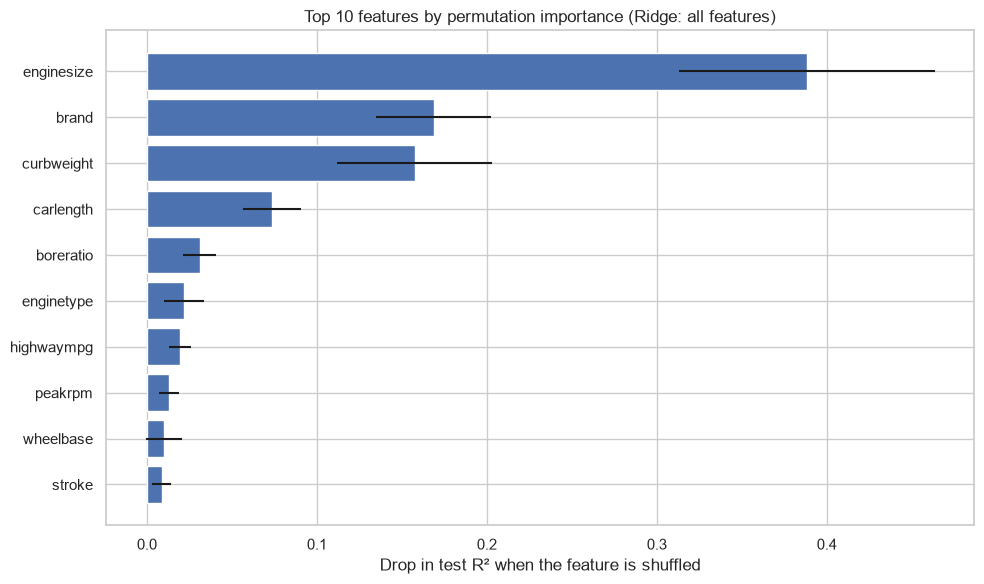

,feature,importance_mean,importance_std
14,enginesize,0.3882,0.0752
23,brand,0.1688,0.0338
11,curbweight,0.1575,0.0455
8,carlength,0.0736,0.0173
16,boreratio,0.0310,0.0096
12,enginetype,0.0215,0.0118
22,highwaympg,0.0194,0.0065
20,peakrpm,0.0130,0.0061
7,wheelbase,0.0101,0.0108
17,stroke,0.0086,0.0056


In [10]:
perm = permutation_importance(final_model, X_test, y_test, n_repeats=30, random_state=RANDOM_STATE, scoring='r2')
importance = pd.DataFrame({
    'feature': X_test.columns,
    'importance_mean': perm.importances_mean,
    'importance_std': perm.importances_std,
}).sort_values('importance_mean', ascending=False)

top = importance.head(10).iloc[::-1]
plt.figure(figsize=(10, 6))
plt.barh(top['feature'], top['importance_mean'], xerr=top['importance_std'], color='#4C72B0')
plt.title(f'Top 10 features by permutation importance ({final_name})')
plt.xlabel('Drop in test R² when the feature is shuffled')
plt.tight_layout()
plt.show()

importance.head(10)

**Engine size, brand and curb weight** dominate the predictions, followed by car length. Every other feature, including fuel economy, body type and drive wheel, changes test R² by less than 0.04 when shuffled.

Permutation importance needs care when features are correlated. Shuffling one feature while a correlated partner stays intact creates unrealistic cars, and the importance gets split between the partners in unpredictable ways. Here engine size, curb weight, car length and horsepower all overlap (Section 4), so their individual rankings are approximate.

# 7. Conclusions

**Regularisation helps.** With all features available, Ridge regression predicts price better than plain OLS (CV RMSE about \$2,370 vs \$2,750) and is more stable across folds, because it controls the heavy multicollinearity among the size, weight and fuel-economy features. On the held-out test set it reaches R² 0.904 with a typical error of about \$1,890, a large improvement on the original three-feature model (R² 0.821, about \$2,720).

**Engine size, brand and curb weight drive the predictions.** The remaining features add little individually.

**Compared with `car_price_mlr.ipynb`** (same split, same 41 test cars):

| Model | Test R² | RMSE | MAE | MAPE |
|---|---|---|---|---|
| Ridge, all features (this notebook) | 0.904 | \$2,757 | \$1,893 | 16.1% |
| Log-price MLR with brand tier (`car_price_mlr.ipynb`) | 0.920 | \$2,513 | \$1,652 | 11.3% |

The smaller log-price model wins, especially on percentage error. Two choices explain it:

- **Modelling log(price)** matches how prices behave: errors are roughly proportional to price, and predictions can't go negative.
- **Brand tiers** (budget, mid, luxury) capture the brand effect with 2 stable coefficients instead of 21 brand dummies, several of which rest on 1–3 cars.

More features with regularisation is not automatically better than a well-specified small model. A natural next step would be Ridge on log(price) with brand tiers, combining both ideas.

**Limitations:** 205 cars from the classic 1985 imports dataset, and a single 41-car test set, so the test scores have a wide margin of error. Permutation importance is approximate for correlated features.